<a href="https://colab.research.google.com/github/Sevin-Tayfehaliverdi/bioinformatics-lab/blob/main/Bio4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Successfully obtained main DNA sequence! Length: 2500 nucleotides

--- 10 Random DNA Fragments Stored in Array ---
Lane 1: 281 base pairs (bp)
Lane 2: 759 base pairs (bp)
Lane 3: 169 base pairs (bp)
Lane 4: 195 base pairs (bp)
Lane 5: 401 base pairs (bp)
Lane 6: 798 base pairs (bp)
Lane 7: 434 base pairs (bp)
Lane 8: 206 base pairs (bp)
Lane 9: 105 base pairs (bp)
Lane 10: 393 base pairs (bp)


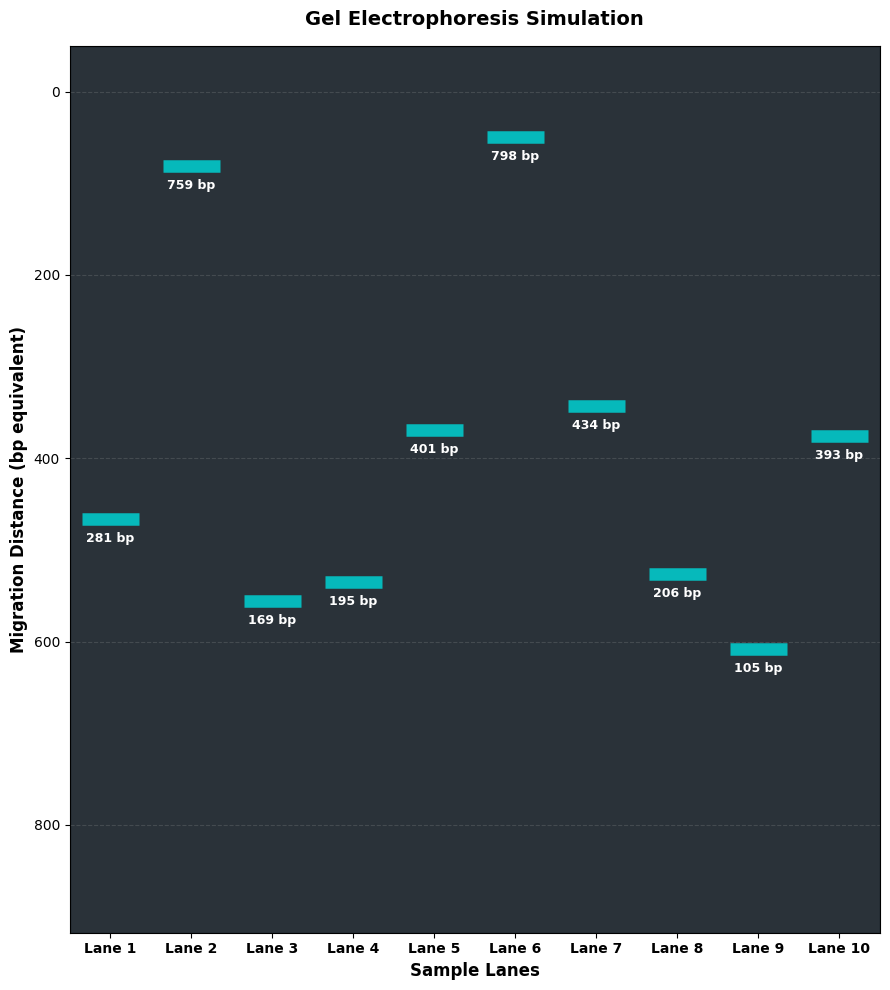

In [2]:
import random
import urllib.request
from Bio import Entrez
import matplotlib.pyplot as plt
import numpy as np

Entrez.email = "student@example.com"

def fetch_ncbi_sequence(accession="NC_001422.1"):
    try:

        handle = Entrez.efetch(db="nucleotide", id=accession, rettype="fasta", retmode="text")
        fasta_record = handle.read()
        handle.close()

        lines = fasta_record.splitlines()
        seq = "".join(line for line in lines if not line.startswith(">"))
        return seq
    except Exception as e:
        print(f"NCBI fetch warning ({e}), using fallback synthetic DNA sequence.")

        bases = ['A', 'C', 'G', 'T']
        return "".join(random.choice(bases) for _ in range(2000))

dna_sequence = fetch_ncbi_sequence("NC_001422.1")
if len(dna_sequence) > 3000:
    dna_sequence = dna_sequence[:2500]
elif len(dna_sequence) < 1000:
    bases = ['A', 'C', 'G', 'T']
    dna_sequence += "".join(random.choice(bases) for _ in range(1500 - len(dna_sequence)))

print(f"Successfully obtained main DNA sequence! Length: {len(dna_sequence)} nucleotides\n")

fragments = []
fragment_lengths = []

for i in range(10):

    frag_len = random.randint(100, min(800, len(dna_sequence) - 50))

    start_pos = random.randint(0, len(dna_sequence) - frag_len)

    fragment = dna_sequence[start_pos : start_pos + frag_len]
    fragments.append(fragment)
    fragment_lengths.append(len(fragment))

print("--- 10 Random DNA Fragments Stored in Array ---")
for idx, length in enumerate(fragment_lengths):
    print(f"Lane {idx + 1}: {length} base pairs (bp)")


plt.figure(figsize=(9, 10))
plt.title("Gel Electrophoresis Simulation", fontsize=14, fontweight='bold', pad=15)

plt.axvspan(-0.5, 9.5, color='#1e272e', alpha=0.95)

max_len = max(fragment_lengths)
min_len = min(fragment_lengths)
plt.ylim(max_len * 1.15, -50)
plt.xlim(-0.5, len(fragments) - 0.5)

for idx, length in enumerate(fragment_lengths):

    migration_distance = (max_len - length) / (max_len - min_len + 1) * (max_len * 0.7) + 50

    plt.hlines(y=migration_distance, xmin=idx - 0.35, xmax=idx + 0.35, colors='#00d2d3', linewidth=9, alpha=0.85)

    plt.text(idx, migration_distance + 25, f"{length} bp", color='white', fontsize=9, ha='center', fontweight='bold')

plt.xticks(range(len(fragments)), [f"Lane {i+1}" for i in range(len(fragments))], color='black', fontsize=10, fontweight='bold')
plt.ylabel("Migration Distance (bp equivalent)", fontsize=12, fontweight='bold')
plt.xlabel("Sample Lanes", fontsize=12, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.2)
plt.tight_layout()
plt.show()


In [ ]:
!pip install biopython


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 14.1 MB/s  0:00:00
